# Part 3E：业绩预期（Performance expectations）

> 组内工作 notebook。说明文字用中文；**图表、表格的文字用英文**，可以直接放进报告。

## 题目在问什么

研究对象：**2004/12/31 的只做多最小方差组合**（3A 的组合②，不是 3D 重新优化的那个）。

**第一部分**：画出 2004/12/31 投入 \$1、按月复利到 2023/07/31 的累计价值，**y 轴用以 2 为底的对数刻度**；同一张图加上投入 \$1 到 MSCI US 指数的累计价值。评述在两次危机中，组合相对大盘的表现是否"符合预期"：

| 危机 | 区间 |
|---|---|
| 全球金融危机（GFC） | 2008/09 – 2009/02 |
| 新冠疫情（COVID） | 2020/02 – 2020/03 |

**第二部分**：在两次危机中**分别**找出累计收益最高（最抗跌）的 10 个行业，评述它们是传统防御行业，还是有些乍一看出人意料（提示：哪些股票其实从新冠中受益？它们历史上是低波动的吗？）。

## 关键约定

- **起点**：2004/12 的值 = \$1，之后用 2005/01 – 2023/07 共 223 个月的收益复利；
- **权重**：固定为 3A 的权重，每月调回目标权重（与 3C 一致）；
- **MSCI US**：用 FF/MSCI 工作簿里的 *MSCI USA Standard (Large+Mid Cap), Gross, USD* 指数点位，转成月度收益（读取逻辑与 Part 2 相同）；
- **危机期间收益**：区间内各月收益复利，例如 GFC = 2008/09 到 2009/02 共 6 个月的累计收益；
- **"历史波动率排名"**：用 1995–2004（也就是优化器当时看到的数据）计算 49 个行业的年化波动率，**1 = 最低，49 = 最高**。另外也给出危机前 10 年的排名作为对照。

## 本 notebook 的输出

| 文件 | 内容 |
|---|---|
| `output/figures/fig_3E_cumulative.png` | 报告主图：\$1 累计价值（log₂ 刻度） |
| `output/figures/fig_3E_top10.png` | 两次危机中最抗跌的 10 个行业 |
| `output/tables/tab_3E_performance.csv` | 全期与两次危机的表现对比 |
| `output/tables/tab_3E_top10_gfc.csv`、`tab_3E_top10_covid.csv` | 两张前 10 名行业表 |
| `output/tables/tab_3E_crisis_contrib.csv` | 危机中各持仓行业对组合收益的贡献 |

## 目录

1. 环境设置 · 2. 读取数据 · 3. \$1 累计价值 · 4. 两次危机中的表现 · 5. 拆解：组合为什么没能抗跌 · 6. 危机中最抗跌的 10 个行业 · 7. 报告用图表 · 8. 写报告时的要点

## 1. 环境设置

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

HERE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "part3_common.py").exists()
            or (p / "part3" / "python_source" / "part3_common.py").exists())
if not (HERE / "part3_common.py").exists():
    HERE = HERE / "part3" / "python_source"
sys.path.insert(0, str(HERE))
import part3_common as p3
from part3_common import config, utils, CN, EN

config.apply_style()
CRISES = {"GFC": config.PERIODS["3E_gfc"], "COVID": config.PERIODS["3E_covid"]}
CRISIS_LABEL = {"GFC": "GFC (Sep 2008 - Feb 2009)", "COVID": "COVID (Feb - Mar 2020)"}
print("投资区间:", config.PERIODS["3E"], "；危机:", CRISES)

投资区间: ('2005-01', '2023-07') ；危机: {'GFC': ('2008-09', '2009-02'), 'COVID': ('2020-02', '2020-03')}


## 2. 读取数据

MSCI 读取后先核对 1995/01 的收益，方便和组员的数字对照（README 的 Cross-check 要求）。

In [2]:
rets = p3.load_industry_returns()
w = p3.load_weights_3A()["mv_long_only"]
msci_all = p3.load_msci_usa()
print(f"MSCI USA 月收益: {msci_all.index[0]} ~ {msci_all.index[-1]}，1995/01 = {msci_all.iloc[0]:.4%}（组内核对用）")

ind = utils.select_period(rets, "3E")
pf = (ind[w.index] @ w).rename("Long-only min-var (as of Dec 2004)")
msci = utils.select_period(msci_all, "3E")
assert len(pf) == len(msci) == 223 and pf.index.equals(msci.index)
print(f"组合与 MSCI 均为 {pf.index[0]} ~ {pf.index[-1]}，{len(pf)} 个月，已对齐 ✓")
print(f"组合持仓（{(w > 0).sum()} 个行业）：" + "、".join(f"{CN[c]} {v:.1%}" for c, v in w[w > 0].sort_values(ascending=False).items()))

MSCI USA 月收益: 1995-01 ~ 2023-07，1995/01 = 2.7810%（组内核对用）
组合与 MSCI 均为 2005-01 ~ 2023-07，223 个月，已对齐 ✓
组合持仓（12 个行业）：公用事业 16.7%、房地产 13.7%、日用消费品 12.3%、农业 10.7%、制药 9.5%、国防军工 9.3%、食品 9.1%、印刷出版 7.7%、医疗器械 5.9%、通信 2.9%、石油天然气 1.6%、贵金属 0.7%


## 3. \$1 累计价值

在 2004/12 补一个起点 1.0，之后逐月复利。

In [3]:
start = pd.Period("2004-12", "M")
def wealth(r):
    return pd.concat([pd.Series({start: 1.0}), utils.cumulative_value(r)])

V_pf, V_msci = wealth(pf), wealth(msci)

def drawdown(V):
    return (V / V.cummax() - 1).min()

perf = pd.DataFrame({
    "Final value of $1 (Jul 2023)": [V_pf.iloc[-1], V_msci.iloc[-1]],
    "Annualized return (geometric)": [utils.annualized_return(pf, "geometric"), utils.annualized_return(msci, "geometric")],
    "Annualized volatility": [utils.annualized_volatility(pf), utils.annualized_volatility(msci)],
    "Maximum drawdown": [drawdown(V_pf), drawdown(V_msci)],
}, index=["Long-only min-var", "MSCI USA"])
for name, (a, b) in CRISES.items():
    perf[f"Cumulative return, {CRISIS_LABEL[name]}"] = [(1 + pf.loc[a:b]).prod() - 1, (1 + msci.loc[a:b]).prod() - 1]
perf.index.name = "Jan 2005 - Jul 2023"
print("CSV →", utils.save_table(perf.T, "tab_3E_performance", float_format="%.6f").relative_to(p3.ROOT))
perf.T.style.format(lambda v: f"${v:.2f}" if v > 1 else f"{v:.1%}")

CSV → output/tables/tab_3E_performance.csv


Jan 2005 - Jul 2023,Long-only min-var,MSCI USA
Final value of $1 (Jul 2023),$4.79,$5.53
Annualized return (geometric),8.8%,9.6%
Annualized volatility,14.3%,15.3%
Maximum drawdown,-45.7%,-50.6%
"Cumulative return, GFC (Sep 2008 - Feb 2009)",-40.3%,-41.8%
"Cumulative return, COVID (Feb - Mar 2020)",-21.2%,-19.8%


> 年化收益这里用**几何平均**（复利增长率），因为问的是 \$1 实际变成了多少钱，和累计价值图是一一对应的。

## 4. 两次危机中的表现

"符合预期"的标准是**比大盘跌得少**（下行保护），而不是一定要赚钱。下面按月列出危机期间的收益，看差距出现在哪几个月。

In [4]:
for name, (a, b) in CRISES.items():
    t = pd.DataFrame({"组合": pf.loc[a:b], "MSCI USA": msci.loc[a:b]})
    t["组合 − MSCI"] = t["组合"] - t["MSCI USA"]
    cum = (1 + t[["组合", "MSCI USA"]]).prod() - 1
    print(f"【{CRISIS_LABEL[name]}】累计：组合 {cum['组合']:.1%}，MSCI {cum['MSCI USA']:.1%}，"
          f"差 {cum['组合'] - cum['MSCI USA']:+.1%}")
    print(t.to_string(float_format=lambda v: f"{v:+.1%}"), "\n")

【GFC (Sep 2008 - Feb 2009)】累计：组合 -40.3%，MSCI -41.8%，差 +1.4%
            组合  MSCI USA  组合 − MSCI
month                              
2008-09  -7.7%     -9.2%      +1.5%
2008-10 -17.3%    -17.1%      -0.2%
2008-11  -8.7%     -7.4%      -1.3%
2008-12  +1.6%     +1.3%      +0.3%
2009-01  -3.3%     -8.1%      +4.9%
2009-02 -12.9%    -10.2%      -2.7% 

【COVID (Feb - Mar 2020)】累计：组合 -21.2%，MSCI -19.8%，差 -1.4%
            组合  MSCI USA  组合 − MSCI
month                              
2020-02  -8.5%     -8.2%      -0.4%
2020-03 -13.9%    -12.7%      -1.2% 



## 5. 拆解：组合为什么没能抗跌

把危机期间组合的收益拆到每个持仓行业：**贡献 ≈ 权重 × 该行业在危机中的累计收益**。因为组合每月调回目标权重，这个拆法是近似值，各行业贡献加总与组合的实际累计收益会略有差异（下面会打印出来对照）。

同时列出该行业在危机中的累计收益在 49 个行业里的排名（1 = 最好），看组合押注的行业到底是不是危机中的"避风港"。

In [5]:
contrib_tabs = {}
for name, (a, b) in CRISES.items():
    cr = (1 + ind.loc[a:b]).prod() - 1
    held = w[w > 0].index
    t = pd.DataFrame({"Weight": w[held], "Industry crisis return": cr[held],
                      "Rank of 49 (1 = best)": cr.rank(ascending=False)[held].astype(int)})
    t["Contribution (≈ weight × return)"] = t["Weight"] * t["Industry crisis return"]
    t = t.sort_values("Contribution (≈ weight × return)")
    t.insert(0, "Industry", [EN[c] for c in t.index])
    contrib_tabs[name] = t
    print(f"【{CRISIS_LABEL[name]}】近似贡献合计 {t.iloc[:, -1].sum():.1%}，组合实际 {(1 + pf.loc[a:b]).prod() - 1:.1%}")
    print(t.assign(行业=[CN[c] for c in t.index]).drop(columns="Industry").to_string(
        float_format=lambda v: f"{v:.1%}"), "\n")

ct = pd.concat({k: v for k, v in contrib_tabs.items()}, names=["Crisis", "Code"])
print("CSV →", utils.save_table(ct, "tab_3E_crisis_contrib", float_format="%.6f").relative_to(p3.ROOT))

【GFC (Sep 2008 - Feb 2009)】近似贡献合计 -39.6%，组合实际 -40.3%
       Weight  Industry crisis return  Rank of 49 (1 = best)  Contribution (≈ weight × return)     行业
RlEst   13.7%                  -67.2%                     45                             -9.2%    房地产
Util    16.7%                  -32.6%                     10                             -5.5%   公用事业
Books    7.7%                  -56.4%                     38                             -4.4%   印刷出版
Hshld   12.3%                  -34.7%                     12                             -4.3%  日用消费品
Guns     9.3%                  -43.6%                     21                             -4.1%   国防军工
Agric   10.7%                  -33.4%                     11                             -3.6%     农业
MedEq    5.9%                  -42.0%                     20                             -2.5%   医疗器械
Drugs    9.5%                  -24.1%                      4                             -2.3%     制药
Food     9.1%                

## 6. 危机中最抗跌的 10 个行业

每次危机分别计算 49 个行业的累计收益，取前 10。额外加三列帮助判断"是不是历史上的低波动行业"：

- **Vol rank 1995–2004**：优化器当时看到的历史波动率排名（1 = 最低，49 = 最高）；
- **Vol rank, 10y pre-crisis**：危机前 10 年的波动率排名，用来看排名在危机前是否已经变了；
- **Min-var weight**：该行业在组合里的权重（0 = 组合没持有）。

In [6]:
vol_rank_seed = utils.select_period(rets, "3_seed").apply(utils.annualized_volatility).rank().astype(int)
top10 = {}
for name, (a, b) in CRISES.items():
    cr = (1 + ind.loc[a:b]).prod() - 1
    pre = rets.loc[:pd.Period(a, "M") - 1].tail(120)
    vol_rank_pre = pre.apply(utils.annualized_volatility).rank().astype(int)
    top = cr.sort_values(ascending=False).head(10).index
    t = pd.DataFrame({
        "Industry": [EN[c] for c in top],
        "Crisis return": cr[top],
        "Vol rank 1995–2004": vol_rank_seed[top],
        f"Vol rank, 10y pre-crisis ({pre.index[0]}–{pre.index[-1]})": vol_rank_pre[top],
        "Min-var weight": w[top],
    })
    t.index.name = "Code"
    top10[name] = t
    held_n = (t["Min-var weight"] > 0).sum()
    print(f"【{CRISIS_LABEL[name]}】前 10 名中组合持有 {held_n} 个；MSCI 同期 {(1 + msci.loc[a:b]).prod() - 1:.1%}")
    print(t.assign(行业=[CN[c] for c in t.index]).drop(columns="Industry").to_string(
        formatters={"Crisis return": "{:.1%}".format, "Min-var weight": "{:.1%}".format}))
    worst = cr.sort_values().head(5)
    print("  最差 5 个：" + "、".join(f"{CN[c]} {v:.0%}" for c, v in worst.items()), "\n")
    utils.save_table(t, f"tab_3E_top10_{name.lower()}", float_format="%.6f")
print("CSV → output/tables/tab_3E_top10_gfc.csv, tab_3E_top10_covid.csv")

【GFC (Sep 2008 - Feb 2009)】前 10 名中组合持有 4 个；MSCI 同期 -41.8%
      Crisis return  Vol rank 1995–2004  Vol rank, 10y pre-crisis (1998-09–2008-08) Min-var weight     行业
Code                                                                                                     
Gold         -11.6%                  48                                          48           0.7%    贵金属
Beer         -22.3%                  22                                          11           0.0%  啤酒与烈酒
PerSv        -24.1%                  21                                          20           0.0%   个人服务
Drugs        -24.1%                   8                                           4           9.5%     制药
Food         -24.3%                   1                                           2           9.1%     食品
Meals        -26.1%                  11                                          13           0.0%   餐饮酒店
Soda         -29.4%                  42                                          42           

【COVID (Feb - Mar 2020)】前 10 名中组合持有 4 个；MSCI 同期 -19.8%
      Crisis return  Vol rank 1995–2004  Vol rank, 10y pre-crisis (2010-02–2020-01) Min-var weight       行业
Code                                                                                                       
Gold          -3.2%                  48                                          48           0.7%      贵金属
Drugs         -7.1%                   8                                           9           9.5%       制药
Rtail        -10.3%                  17                                          10           0.0%       零售
Smoke        -12.7%                  44                                          23           0.0%       烟草
Food         -13.1%                   1                                           4           9.1%       食品
Softw        -14.6%                  45                                          14           0.0%       软件
Hshld        -14.6%                   5                                          

CSV → output/tables/tab_3E_top10_gfc.csv, tab_3E_top10_covid.csv


## 7. 报告用图表

### 7.1 主图：\$1 累计价值（log₂ 刻度）

y 轴每往上一格，财富翻一倍（\$1 → \$2 → \$4）。对数刻度下，**同样的高度差 = 同样的百分比涨跌**，所以 2008 年和 2020 年的下跌可以直接比较。阴影是题目指定的两段危机，旁边标注了两条线在危机中的累计收益。

PNG → output/figures/fig_3E_cumulative.png


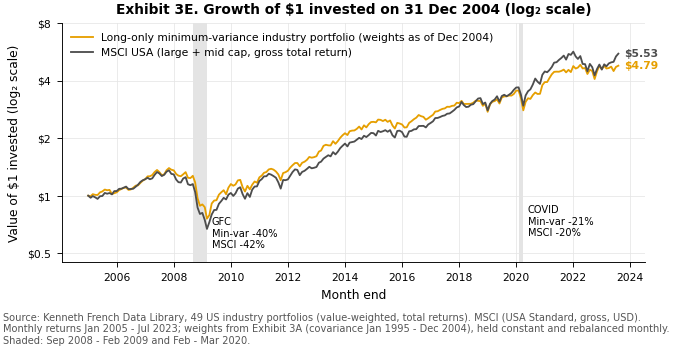

In [7]:
PF_C = p3.PF_COLORS["mv_long_only"]
x_pf = V_pf.index.to_timestamp(how="end")

fig, ax = utils.new_fig("full")
ax.plot(x_pf, V_pf.to_numpy(), color=PF_C, label="Long-only minimum-variance industry portfolio (weights as of Dec 2004)")
ax.plot(x_pf, V_msci.to_numpy(), color=config.COLOR_MARKET, label="MSCI USA (large + mid cap, gross total return)")
ax.set_yscale("log", base=2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:g}"))
ax.set_ylim(0.45, 8)

for name, (a, b) in CRISES.items():
    xa, xb = pd.Period(a, "M").to_timestamp(), pd.Period(b, "M").to_timestamp(how="end")
    ax.axvspan(xa, xb, color="#D9D9D9", alpha=0.7, lw=0)
    rp, rm = perf.loc["Long-only min-var", f"Cumulative return, {CRISIS_LABEL[name]}"], perf.loc["MSCI USA", f"Cumulative return, {CRISIS_LABEL[name]}"]
    ax.text(xb + pd.Timedelta(days=60), 0.52 if name == "GFC" else 0.6,
            f"{name}\nMin-var {rp:.0%}\nMSCI {rm:.0%}", fontsize=config.FONT_SMALL - 0.5, va="bottom")
for V, c in [(V_pf, PF_C), (V_msci, config.COLOR_MARKET)]:
    ax.annotate(f"${V.iloc[-1]:.2f}", (x_pf[-1], V.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=config.FONT_SMALL, color=c, fontweight="bold")
ax.set_ylabel("Value of $1 invested (log₂ scale)")
ax.set_xlabel("Month end")
ax.legend(loc="upper left")
ax.set_title("Exhibit 3E. Growth of $1 invested on 31 Dec 2004 (log₂ scale)")
src = (p3.SOURCE_FF49 + " MSCI (USA Standard, gross, USD).\nMonthly returns Jan 2005 - Jul 2023; weights from Exhibit 3A "
       "(covariance Jan 1995 - Dec 2004), held constant and rebalanced monthly.\nShaded: Sep 2008 - Feb 2009 and Feb - Mar 2020.")
print("PNG →", utils.save_fig(fig, "fig_3E_cumulative", source=src).relative_to(p3.ROOT))
plt.show()

### 7.2 两次危机中最抗跌的 10 个行业

左右两栏分别是 GFC 和 COVID。**橙色 = 组合持有的行业，灰色 = 组合没持有**；行业名后面括号里是 1995–2004 的波动率排名（1 = 最低，49 = 最高）。每栏最下面两根加粗的柱子是组合和 MSCI 在同期的累计收益，作为比较基准。

PNG → output/figures/fig_3E_top10.png


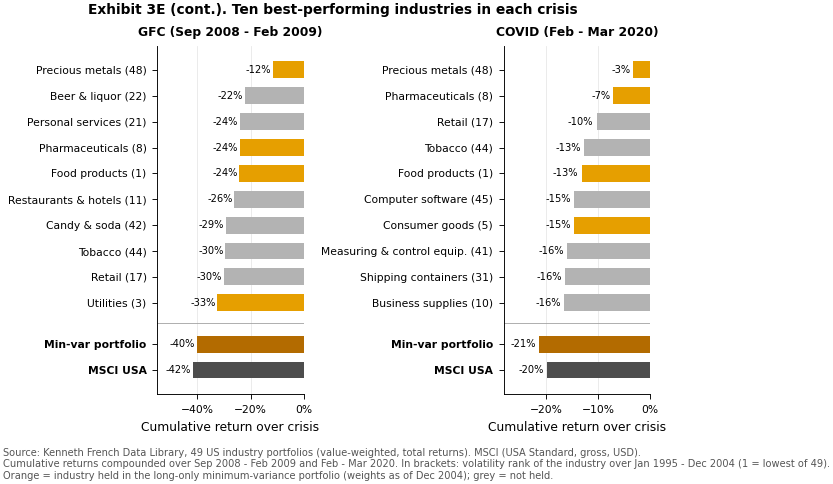

In [8]:
fig, axes = utils.new_fig("tall", 1, 2, sharex=False)
BENCH_PF_C = "#B36B00"
for ax, (name, t) in zip(axes, top10.items()):
    a, b = CRISES[name]
    rp, rm = (1 + pf.loc[a:b]).prod() - 1, (1 + msci.loc[a:b]).prod() - 1
    labels = [f"{EN[c]} ({r})" for c, r in zip(t.index, t["Vol rank 1995–2004"])] + ["Min-var portfolio", "MSCI USA"]
    vals = list(t["Crisis return"]) + [rp, rm]
    colors = [PF_C if v > 0 else "#B3B3B3" for v in t["Min-var weight"]] + [BENCH_PF_C, config.COLOR_MARKET]
    y = -np.r_[np.arange(10), [10.6, 11.6]]          # 最好的在最上面；两根基准柱放在最下面
    ax.barh(y, vals, color=colors, height=0.65)
    ax.axhline((y[9] + y[10]) / 2, color="#999999", linewidth=0.5)
    ax.set_yticks(y, labels)
    for tick in ax.get_yticklabels()[-2:]:
        tick.set_fontweight("bold")
    for yi, v in zip(y, vals):
        ax.text(v - 0.006, yi, f"{v:.0%}", ha="right", va="center", fontsize=config.FONT_SMALL - 0.5)
    ax.set_xlim(min(vals) * 1.32, 0)
    utils.percent_axis(ax, "x")
    ax.xaxis.set_major_locator(MultipleLocator(0.2 if min(vals) < -0.3 else 0.1))
    ax.set_xlabel("Cumulative return over crisis")
    ax.set_title(CRISIS_LABEL[name], fontsize=config.FONT_SIZE)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
from matplotlib.patches import Patch

fig.suptitle("Exhibit 3E (cont.). Ten best-performing industries in each crisis", fontsize=config.FONT_TITLE, fontweight="bold")
src = (p3.SOURCE_FF49 + " MSCI (USA Standard, gross, USD).\n"
       "Cumulative returns compounded over Sep 2008 - Feb 2009 and Feb - Mar 2020. In brackets: volatility rank of the industry "
       "over Jan 1995 - Dec 2004 (1 = lowest of 49).\nOrange = industry held in the long-only minimum-variance portfolio (weights as of Dec 2004); grey = not held.")
print("PNG →", utils.save_fig(fig, "fig_3E_top10", source=src).relative_to(p3.ROOT))
plt.show()

## 8. 写报告时的要点

> 下面的数字来自本 notebook 的运行结果（数据固定，重跑结果不变）。

### 结果速览

| 2005/01 – 2023/07 | 最小方差（只做多，2004 年权重） | MSCI USA |
|---|---|---|
| \$1 变成 | \$4.79 | **\$5.53** |
| 年化收益（几何） | 8.8% | 9.6% |
| 年化波动率 | **14.3%** | 15.3% |
| 最大回撤 | **−45.7%** | −50.6% |
| GFC 2008/09–2009/02 累计 | −40.3% | −41.8%（组合仅好 1.4 个百分点） |
| COVID 2020/02–03 累计 | −21.2% | −19.8%（组合**反而差** 1.4 个百分点） |

### 第一部分：防御策略在危机中是否符合预期？——基本**没有**

1. **全期来看有一点防御效果**：波动率低 1 个百分点，最大回撤小约 5 个百分点。2009–2019 年组合大部分时间领先于大盘，但 2020 年以后被大盘（尤其是科技股主导的反弹）超越，最终 \$4.79 对 \$5.53。
2. **但在两次指定的危机里几乎没起到保护作用**：GFC 只比大盘少跌 1.4 个百分点，COVID 甚至多跌 1.4 个百分点。对一个以"最低波动"为目标的防御组合来说，这**不符合预期**。
3. **主要原因是押错了"低波动"行业，尤其是房地产**。房地产在 1995–2004 年波动很低，所以拿到了第二大权重 13.7%。但它恰恰是两次危机的重灾区：
    - GFC 中跌 67%（49 个行业里排第 45），一个行业就拖累组合约 9.2 个百分点；
    - COVID 中跌 42%（排第 46），拖累约 5.8 个百分点。

   另外，印刷出版（7.7%）在 GFC 中跌了 56%；公用事业（16.7%，最大权重）在 COVID 中跌了 22%，比大盘还多。
4. **这说明"历史低波动"不等于"危机中抗跌"**：
    - 组合权重来自 1995–2004 年的数据，到 2008 和 2020 年已经过时（呼应 3C、3D 的结论）；
    - 每次危机的性质不同：GFC 是房地产和金融危机，COVID 是封城带来的经济活动停摆，受冲击的行业不一样；
    - 危机时行业间相关性急升（3C 中平均相关性从 0.40 升到 0.59），分散化的效果在最需要的时候变弱。

### 第二部分：危机中最抗跌的 10 个行业

**GFC（2008/09–2009/02）**：贵金属、啤酒与烈酒、个人服务、制药、食品、餐饮酒店、糖果与软饮、烟草、零售、公用事业。
- **大多是传统防御型行业**（必需消费品、医药、公用事业），符合教科书预期；
- **出人意料的是贵金属**：它在 1995–2004 年是第二高波动的行业（排名 48/49），却在危机中跌得最少（−12%），因为黄金是避险资产。**低波动 ≠ 避险**；
- 烟草（44）和糖果与软饮（42）业务上是防御型，但 1995–2004 年波动很高（排名靠后），所以组合没有持有。

**COVID（2020/02–03）**：贵金属、制药、零售、烟草、食品、软件、日用消费品、测量与控制设备、包装容器、商业用品/纸业。
- 一部分仍是传统防御型（制药、食品、日用消费品、烟草）；
- **出人意料的是"疫情受益"行业**：软件（远程办公）、零售（电商、超市囤货）、包装容器（线上购物和外卖的包装需求）、测量与控制设备。这正是题目提示所指；
- **这些行业历史上是高波动的**：软件在 1995–2004 年的波动率排名是 45/49，测量与控制设备是 41/49。最小方差组合按设计就会避开它们。

**两次危机的共同点**：前 10 名中组合都只持有 4 个，其中贵金属只有 0.7%。最差的 5 个行业里，两次都有房地产，而它是组合的第二大持仓。

**一个延伸观察**：如果改用危机前 10 年的波动率排名，软件在 COVID 前已经降到第 14 名，测量与控制设备降到第 20 名。也就是说，"哪些行业是低波动的"本身在变化。这再次说明定期重新估计的必要性（呼应 3D）。

### 英文写法参考（可改写进报告）

> Over Jan 2005 – Jul 2023, \$1 invested in the long-only minimum-variance portfolio grew to \$4.79, versus \$5.53 for the MSCI USA index, with somewhat lower volatility (14.3% vs 15.3%) and a smaller maximum drawdown (−45.7% vs −50.6%). However, the defensive strategy did not perform as expected in the two crises: it lost 40.3% during the GFC (Sep 2008 – Feb 2009) versus 41.8% for the market, and 21.2% during the COVID sell-off (Feb – Mar 2020), slightly more than the market's 19.8%. The main reason is its 13.7% weight in Real Estate, a low-volatility industry in 1995–2004 that was among the five worst performers in both crises (−67% and −42%). The industries that held up best during the GFC were mostly traditional defensives (food, beverages, pharmaceuticals, tobacco, utilities), together with precious metals, a safe haven despite being the second most volatile industry historically. During COVID, the list also includes "stay-at-home" beneficiaries such as software, retail and shipping containers. Software, for example, ranked 45th of 49 by volatility in 1995–2004, so a minimum-variance portfolio excludes it by design. Historical low volatility is therefore no guarantee of crisis protection: which industries are defensive depends on the nature of the shock, and both covariances and the set of low-volatility industries change over time.

### 备注

- MSCI 读取方式与 Part 2 相同；1995/01 的 MSCI USA 月收益是 **2.7810%**，合并前可以和其他组员核对；
- FF 行业组合包含 CRSP 全部股票（含小盘股），MSCI USA 只含大中盘股，两者的股票池不完全相同。比较时可以在脚注里提一句；
- 危机贡献是"权重 × 行业累计收益"的近似拆分（组合每月调回权重，所以不严格可加），GFC 近似合计 −39.6%，实际 −40.3%，足够用来说明问题；
- 报告篇幅紧张的话，`fig_3E_top10.png` 一张图就能覆盖第二部分，前 10 名的表格可以不放。